# 🍷 Red Wine Quality Prediction
### Predictive Modeling Practical — Classification Model

---

**Dataset:** Red Wine Quality Dataset (UCI Machine Learning Repository / Kaggle)  
**Task:** Binary Classification — Predict whether a wine is **Good** (quality ≥ 6) or **Poor** (quality < 6)  
**Model Used:** Random Forest Classifier  

**Workflow:**
1. Dataset Selection & Loading
2. Exploratory Data Analysis (EDA)
3. Data Preprocessing & Cleaning
4. Train-Test Split
5. Model Selection & Training
6. Model Evaluation with Metrics
7. Visualizations

---
## Step 1 — Import Libraries

In [ ]:
# ── Core data libraries ──────────────────────────────────────────────────────
import pandas as pd          # For loading and manipulating tabular data
import numpy as np           # For numerical operations

# ── Visualization libraries ──────────────────────────────────────────────────
import matplotlib.pyplot as plt   # Base plotting library
import seaborn as sns             # High-level statistical visualizations

# ── Scikit-learn: Preprocessing ──────────────────────────────────────────────
from sklearn.model_selection import train_test_split   # Split data into train/test
from sklearn.preprocessing import StandardScaler       # Normalize feature values

# ── Scikit-learn: Models ─────────────────────────────────────────────────────
from sklearn.ensemble import RandomForestClassifier    # Main model
from sklearn.linear_model import LogisticRegression   # Baseline comparison model
from sklearn.tree import DecisionTreeClassifier        # Another comparison model

# ── Scikit-learn: Evaluation Metrics ─────────────────────────────────────────
from sklearn.metrics import (
    accuracy_score,          # Overall correct predictions / total predictions
    precision_score,         # Of all predicted 'Good', how many actually are Good
    recall_score,x            # Of all actual 'Good', how many did we correctly find
    f1_score,                # Harmonic mean of Precision and Recall
    confusion_matrix,        # Table showing TP, FP, TN, FN
    classification_report,   # Full metric summary
    roc_auc_score,           # Area Under the ROC Curve
    RocCurveDisplay          # For plotting the ROC curve
)

# ── Utility ───────────────────────────────────────────────────────────────────
import warnings
warnings.filterwarnings('ignore')   # Suppress minor version warnings

sns.set_theme(style='whitegrid')    # Clean graph background
plt.rcParams['figure.dpi'] = 110    # Sharper figure output

print('✅ All libraries imported successfully!')

✅ All libraries imported successfully!


---
## Step 2 — Load the Dataset

> **About the Dataset:**  
> The **Red Wine Quality** dataset was created by Paulo Cortez et al. and is hosted on the UCI ML Repository and Kaggle.  
> It contains **1,599 samples** of Portuguese *Vinho Verde* red wine with **11 physicochemical input features** and a quality score (0–10).  
> We load it directly from its public URL — no manual download needed.

In [2]:
# ── Load dataset directly from UCI repository ─────────────────────────────────
# The CSV uses semicolons (;) as separators, not commas
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv'
df = pd.read_csv(url, sep=';')

print(f'Dataset loaded successfully!')
print(f'Shape: {df.shape[0]} rows × {df.shape[1]} columns\n')
df.head()

Dataset loaded successfully!
Shape: 1599 rows × 12 columns



,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


---
## Step 3 — Exploratory Data Analysis (EDA)

Before modeling, we need to **understand the data** — its structure, distributions, and relationships.

In [3]:
# ── Basic structure info ───────────────────────────────────────────────────────
# Shows column names, non-null count, and datatypes
print('=== Dataset Info ===')
df.info()

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [4]:
# ── Statistical summary ────────────────────────────────────────────────────────
# Shows min, max, mean, std, quartiles for each column
print('=== Statistical Summary ===')
df.describe().round(2)

=== Statistical Summary ===


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00
mean,8.32,0.53,0.27,2.54,0.09,15.87,46.47,1.00,3.31,0.66,10.42,5.64
std,1.74,0.18,0.19,1.41,0.05,10.46,32.90,0.00,0.15,0.17,1.07,0.81
min,4.60,0.12,0.00,0.90,0.01,1.00,6.00,0.99,2.74,0.33,8.40,3.00
25%,7.10,0.39,0.09,1.90,0.07,7.00,22.00,1.00,3.21,0.55,9.50,5.00
50%,7.90,0.52,0.26,2.20,0.08,14.00,38.00,1.00,3.31,0.62,10.20,6.00
75%,9.20,0.64,0.42,2.60,0.09,21.00,62.00,1.00,3.40,0.73,11.10,6.00
max,15.90,1.58,1.00,15.50,0.61,72.00,289.00,1.00,4.01,2.00,14.90,8.00


In [5]:
# ── Check for missing values ───────────────────────────────────────────────────
# isnull() returns True for NaN cells; .sum() counts them per column
missing = df.isnull().sum()
print('=== Missing Values per Column ===')
print(missing)
print(f'\nTotal missing values: {missing.sum()}')

=== Missing Values per Column ===
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Total missing values: 0


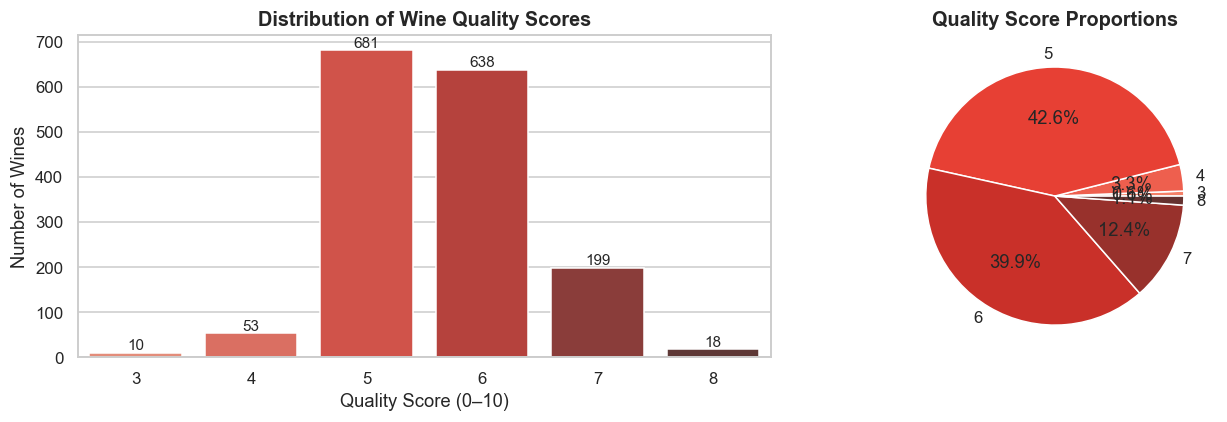

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


In [6]:
# ── Distribution of the target variable (quality score) ───────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Count plot: how many wines have each quality score
sns.countplot(x='quality', data=df, palette='Reds_d', ax=axes[0])
axes[0].set_title('Distribution of Wine Quality Scores', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Quality Score (0–10)')
axes[0].set_ylabel('Number of Wines')

# Add count labels on each bar
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10)

# Pie chart: percentage breakdown
quality_counts = df['quality'].value_counts().sort_index()
axes[1].pie(quality_counts, labels=quality_counts.index, autopct='%1.1f%%',
            colors=sns.color_palette('Reds_d', len(quality_counts)))
axes[1].set_title('Quality Score Proportions', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()
print(df['quality'].value_counts().sort_index())

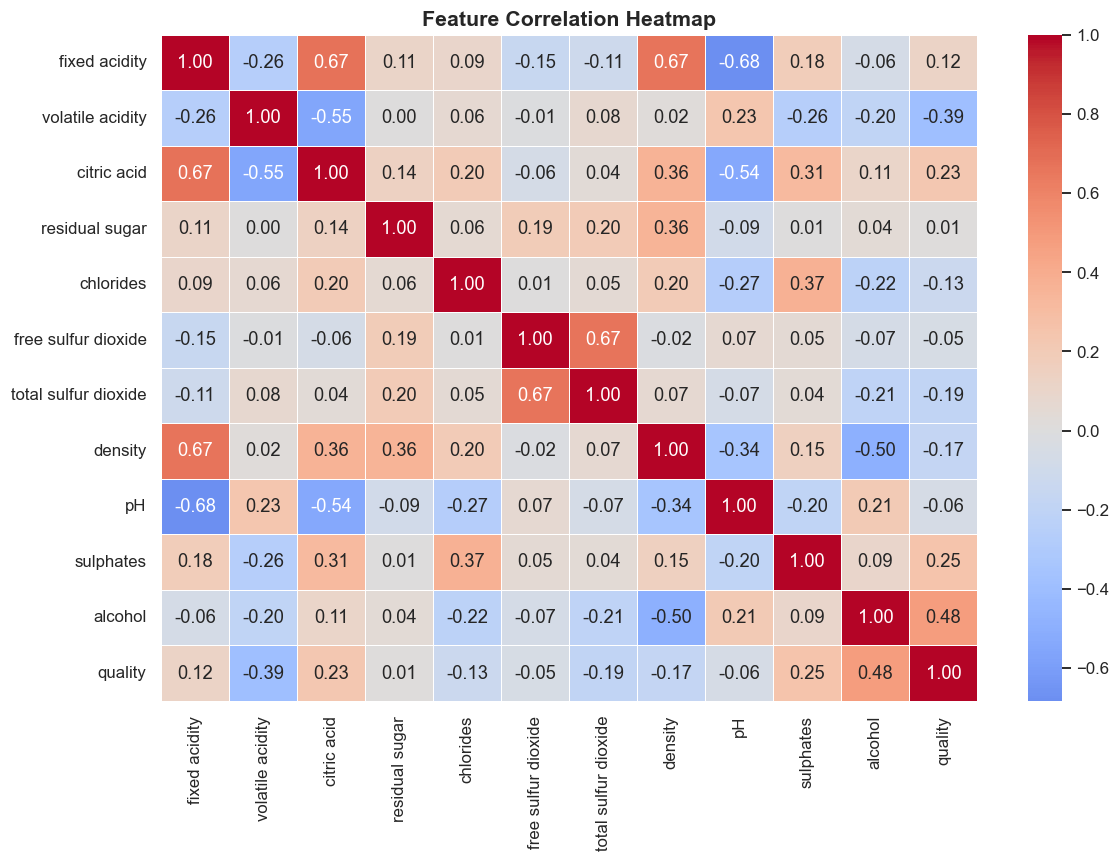


Correlation of each feature with wine quality:
alcohol                 0.476
sulphates               0.251
citric acid             0.226
fixed acidity           0.124
residual sugar          0.014
free sulfur dioxide    -0.051
pH                     -0.058
chlorides              -0.129
density                -0.175
total sulfur dioxide   -0.185
volatile acidity       -0.391
Name: quality, dtype: float64


In [7]:
# ── Correlation Heatmap ────────────────────────────────────────────────────────
# Correlation shows how strongly two features move together (-1 to +1)
# +1 = perfect positive, -1 = perfect negative, 0 = no relation
plt.figure(figsize=(11, 8))
corr_matrix = df.corr()   # Compute pairwise Pearson correlation
sns.heatmap(
    corr_matrix,
    annot=True,          # Show correlation values inside boxes
    fmt='.2f',           # Round to 2 decimal places
    cmap='coolwarm',     # Red = positive, Blue = negative
    center=0,
    linewidths=0.5
)
plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Top correlations with quality
print('\nCorrelation of each feature with wine quality:')
print(corr_matrix['quality'].sort_values(ascending=False).drop('quality').round(3))

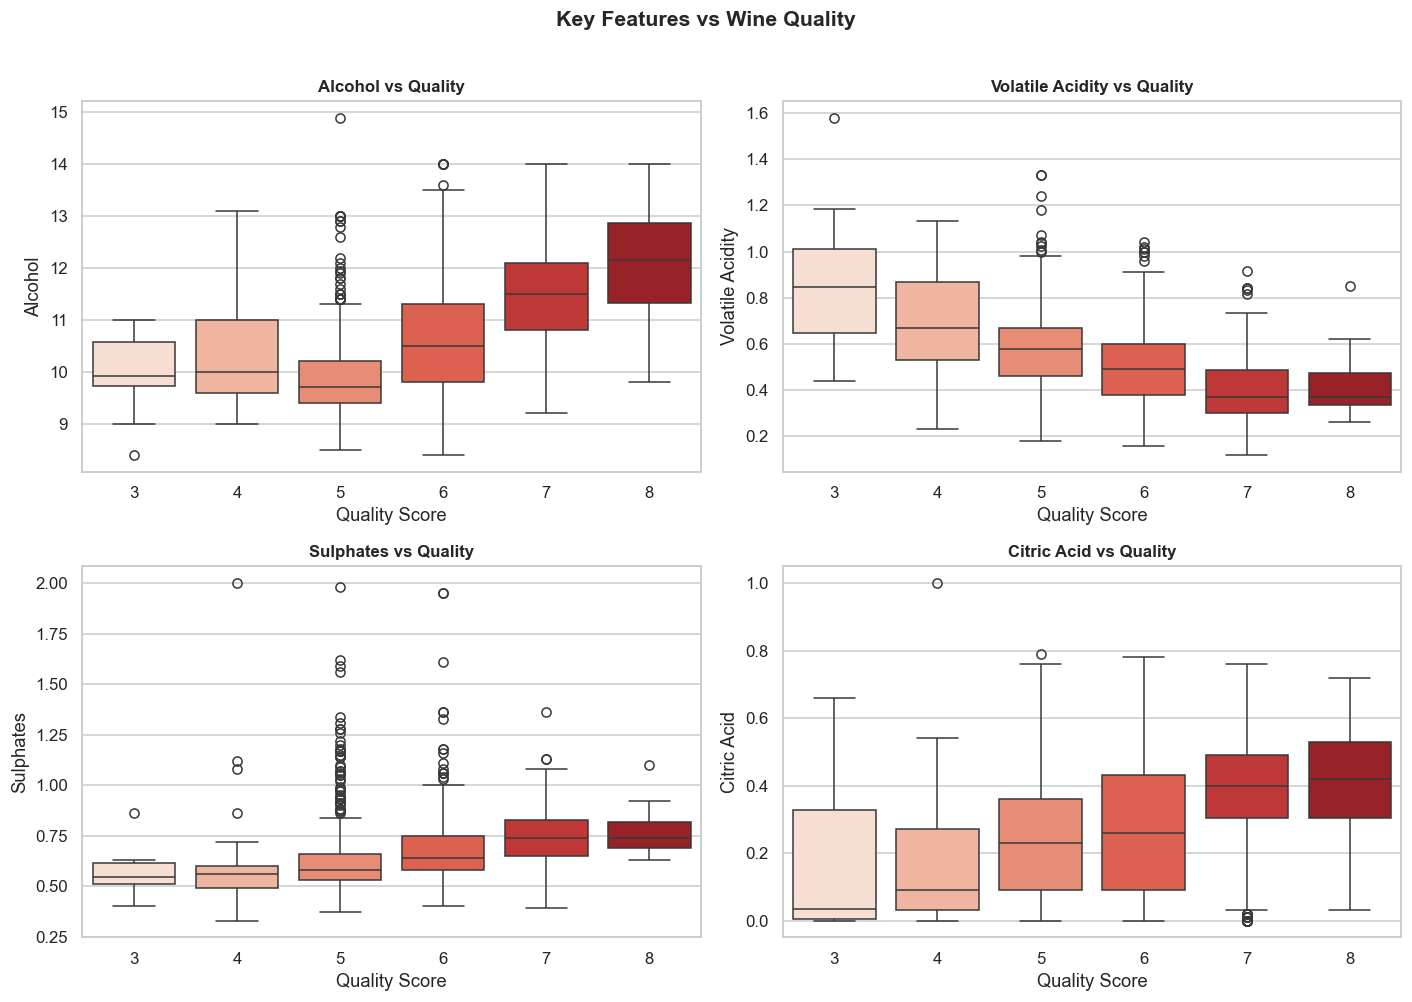

In [8]:
# ── Box Plots: Feature distributions across quality scores ────────────────────
# A box plot shows median, quartiles, and outliers for each group
key_features = ['alcohol', 'volatile acidity', 'sulphates', 'citric acid']

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()   # Convert 2D array to 1D for easy indexing

for i, feature in enumerate(key_features):
    sns.boxplot(x='quality', y=feature, data=df,
                palette='Reds', ax=axes[i])
    axes[i].set_title(f'{feature.title()} vs Quality', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Quality Score')
    axes[i].set_ylabel(feature.title())

plt.suptitle('Key Features vs Wine Quality', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

---
## Step 4 — Data Preprocessing & Cleaning

**What we do here:**
1. Create a binary target column (`good_wine`)
2. Check and handle duplicates
3. Handle outliers using IQR capping
4. Separate features (X) and target (y)
5. Scale features using StandardScaler

Target variable created: good_wine
Value counts:
good_wine
1    855
0    744
Name: count, dtype: int64

0 = Poor Wine (quality < 6): 744 samples
1 = Good Wine (quality >= 6): 855 samples


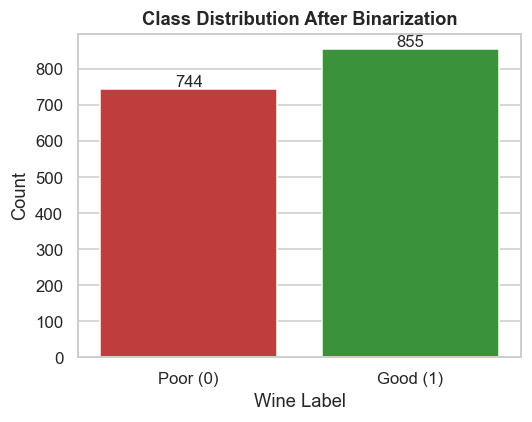

In [9]:
# ── 4.1  Create Binary Target Column ──────────────────────────────────────────
# Original quality is 0–10. We convert it to binary:
#   quality >= 6  →  1  (Good Wine)
#   quality <  6  →  0  (Poor Wine)
# This makes it a binary classification problem.

df['good_wine'] = (df['quality'] >= 6).astype(int)

print('Target variable created: good_wine')
print('Value counts:')
print(df['good_wine'].value_counts())
print(f"\n0 = Poor Wine (quality < 6): {(df['good_wine']==0).sum()} samples")
print(f"1 = Good Wine (quality >= 6): {(df['good_wine']==1).sum()} samples")

# Visual: class balance
plt.figure(figsize=(5, 4))
sns.countplot(x='good_wine', data=df,
              palette=['#d62728', '#2ca02c'])
plt.xticks([0, 1], ['Poor (0)', 'Good (1)'])
plt.title('Class Distribution After Binarization', fontweight='bold')
plt.xlabel('Wine Label')
plt.ylabel('Count')
for p in plt.gca().patches:
    plt.gca().annotate(f'{int(p.get_height())}',
                       (p.get_x() + p.get_width()/2, p.get_height()),
                       ha='center', va='bottom', fontsize=11)
plt.tight_layout()
plt.show()

In [10]:
# ── 4.2  Handle Duplicates ────────────────────────────────────────────────────
# Duplicate rows can bias the model — we remove them
print(f'Rows before removing duplicates: {len(df)}')
df.drop_duplicates(inplace=True)   # inplace=True modifies the dataframe directly
print(f'Rows after removing duplicates:  {len(df)}')

Rows before removing duplicates: 1599
Rows after removing duplicates:  1359


In [11]:
# ── 4.3  Handle Outliers using IQR Capping ────────────────────────────────────
# IQR = Interquartile Range = Q3 - Q1
# Any value below Q1 - 1.5*IQR or above Q3 + 1.5*IQR is considered an outlier.
# Instead of REMOVING outliers (losing data), we CAP them at the boundary.

feature_cols = [col for col in df.columns if col not in ['quality', 'good_wine']]

print('Applying IQR capping to remove outlier influence...')
for col in feature_cols:
    Q1 = df[col].quantile(0.25)      # 25th percentile
    Q3 = df[col].quantile(0.75)      # 75th percentile
    IQR = Q3 - Q1                    # Interquartile range
    lower = Q1 - 1.5 * IQR          # Lower fence
    upper = Q3 + 1.5 * IQR          # Upper fence
    # np.clip replaces values below lower with lower, and above upper with upper
    df[col] = np.clip(df[col], lower, upper)

print('✅ Outlier capping complete.')
print(f'Dataset shape after preprocessing: {df.shape}')

Applying IQR capping to remove outlier influence...


✅ Outlier capping complete.
Dataset shape after preprocessing: (1359, 13)


In [12]:
# ── 4.4  Separate Features (X) and Target (y) ─────────────────────────────────
# X = all columns except the target labels
# y = only the target column (good_wine)

X = df.drop(columns=['quality', 'good_wine'])   # Feature matrix
y = df['good_wine']                              # Target vector

print(f'Feature matrix X shape: {X.shape}')   # (samples, features)
print(f'Target vector y shape:  {y.shape}')   # (samples,)
print(f'\nFeatures used:\n{list(X.columns)}')

Feature matrix X shape: (1359, 11)
Target vector y shape:  (1359,)

Features used:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


In [13]:
# ── 4.5  Feature Scaling with StandardScaler ──────────────────────────────────
# StandardScaler transforms each feature to have:
#   mean = 0  and  standard deviation = 1
# Formula: z = (x - mean) / std_dev
# This prevents features with large values (like 'total sulfur dioxide')
# from dominating features with small values (like 'citric acid').

# NOTE: We scale AFTER train-test split to prevent data leakage
# (We'll apply the scaler only after splitting — see next step)

print('StandardScaler will be applied after splitting. Ready for Step 5.')
print(f'\nSample feature values BEFORE scaling:')
X.describe().round(3)

StandardScaler will be applied after splitting. Ready for Step 5.

Sample feature values BEFORE scaling:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
count,1359.000,1359.000,1359.000,1359.000,1359.000,1359.000,1359.000,1359.000,1359.000,1359.000,1359.000
mean,8.284,0.528,0.272,2.324,0.081,15.714,46.093,0.997,3.309,0.650,10.429
std,1.658,0.177,0.195,0.608,0.018,9.853,30.878,0.002,0.150,0.137,1.071
min,4.600,0.120,0.000,0.900,0.039,1.000,6.000,0.992,2.925,0.330,8.400
25%,7.100,0.390,0.090,1.900,0.070,7.000,22.000,0.996,3.210,0.550,9.500
50%,7.900,0.520,0.260,2.200,0.079,14.000,38.000,0.997,3.310,0.620,10.200
75%,9.200,0.640,0.430,2.600,0.091,21.000,63.000,0.998,3.400,0.730,11.100
max,12.350,1.015,0.940,3.650,0.122,42.000,124.500,1.001,3.685,1.000,13.500


---
## Step 5 — Train-Test Split

We split data into:
- **Training set (80%)** — used to teach the model patterns
- **Test set (20%)** — used to evaluate how well the model generalizes to unseen data

`random_state=42` ensures reproducibility (same split every time).  
`stratify=y` ensures both sets have the same class ratio as the original data.

In [14]:
# ── Train-Test Split ──────────────────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,      # 20% of data goes to test set
    random_state=42,     # Fixed seed for reproducibility
    stratify=y           # Maintains class balance in both splits
)

print('=== Train-Test Split Complete ===')
print(f'Total samples  : {len(X)}')
print(f'Training set   : {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'Test set       : {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.0f}%)')
print(f'\nClass ratio in Training set:\n{y_train.value_counts(normalize=True).round(3)}')
print(f'\nClass ratio in Test set:\n{y_test.value_counts(normalize=True).round(3)}')

=== Train-Test Split Complete ===
Total samples  : 1359
Training set   : 1087 samples (80%)
Test set       : 272 samples (20%)

Class ratio in Training set:
good_wine
1    0.529
0    0.471
Name: proportion, dtype: float64

Class ratio in Test set:
good_wine
1    0.529
0    0.471
Name: proportion, dtype: float64


In [15]:
# ── Apply StandardScaler AFTER Splitting ─────────────────────────────────────
# IMPORTANT: We fit the scaler ONLY on training data
# Then transform both train and test using those same training statistics.
# This avoids DATA LEAKAGE (test data information leaking into preprocessing).

scaler = StandardScaler()

# fit_transform: computes mean & std from X_train, then scales it
X_train_scaled = scaler.fit_transform(X_train)

# transform only: uses the already-computed mean & std from training
X_test_scaled = scaler.transform(X_test)

print('✅ Scaling applied successfully.')
print(f'\nTraining feature values AFTER scaling (mean ≈ 0, std ≈ 1):')
print(pd.DataFrame(X_train_scaled, columns=X.columns).describe().round(2))

✅ Scaling applied successfully.

Training feature values AFTER scaling (mean ≈ 0, std ≈ 1):
       fixed acidity  volatile acidity  citric acid  residual sugar  \
count        1087.00           1087.00      1087.00         1087.00   
mean           -0.00             -0.00        -0.00           -0.00   
std             1.00              1.00         1.00            1.00   
min            -2.15             -2.29        -1.39           -2.35   
25%            -0.71             -0.78        -0.93           -0.71   
50%            -0.23             -0.05        -0.07           -0.22   
75%             0.53              0.65         0.80            0.43   
max             2.45              2.72         3.39            2.15   

       chlorides  free sulfur dioxide  total sulfur dioxide  density       pH  \
count    1087.00              1087.00               1087.00  1087.00  1087.00   
mean       -0.00                 0.00                 -0.00     0.00    -0.00   
std         1.00         

---
## Step 6 — Model Selection & Training

We train **3 models** and compare their performance:

| Model | How it works |
|---|---|
| Logistic Regression | Finds a linear decision boundary using sigmoid function |
| Decision Tree | Splits data using if-else rules on features |
| **Random Forest** | Builds many Decision Trees and votes on the final answer |

**Random Forest** is our primary model — it handles non-linear patterns, is robust to noise, and gives feature importance.

In [16]:
# ── Define the models ──────────────────────────────────────────────────────────
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree':       DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=100, max_depth=10,
                                                  random_state=42, n_jobs=-1)
    # n_estimators=100  → 100 decision trees in the forest
    # max_depth=10      → each tree can be at most 10 levels deep
    # n_jobs=-1         → use all CPU cores for parallel training
}

results = {}   # Dictionary to store evaluation results

print('Training all models...\n')
for name, model in models.items():
    model.fit(X_train_scaled, y_train)         # Train the model
    y_pred = model.predict(X_test_scaled)      # Make predictions on test data
    y_prob = model.predict_proba(X_test_scaled)[:, 1]  # Probability of class 1

    # Calculate metrics
    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec  = recall_score(y_test, y_pred)
    f1   = f1_score(y_test, y_pred)
    auc  = roc_auc_score(y_test, y_prob)

    results[name] = {'Accuracy': acc, 'Precision': prec,
                     'Recall': rec, 'F1 Score': f1, 'ROC-AUC': auc}
    print(f'[{name}]')
    print(f'  Accuracy : {acc:.4f}  |  Precision: {prec:.4f}')
    print(f'  Recall   : {rec:.4f}  |  F1 Score : {f1:.4f}  |  AUC: {auc:.4f}\n')

print('✅ All models trained and evaluated!')

Training all models...

[Logistic Regression]
  Accuracy : 0.7206  |  Precision: 0.7464
  Recall   : 0.7153  |  F1 Score : 0.7305  |  AUC: 0.8150

[Decision Tree]
  Accuracy : 0.6875  |  Precision: 0.7092
  Recall   : 0.6944  |  F1 Score : 0.7018  |  AUC: 0.7629

[Random Forest]
  Accuracy : 0.7610  |  Precision: 0.7842
  Recall   : 0.7569  |  F1 Score : 0.7703  |  AUC: 0.8339

✅ All models trained and evaluated!


---
## Step 7 — Model Evaluation & Visualizations

We evaluate the **best model (Random Forest)** in depth using:
- Comparison Table
- Confusion Matrix
- Classification Report
- ROC Curve
- Feature Importance

In [17]:
# ── 7.1  Model Comparison Table ───────────────────────────────────────────────
results_df = pd.DataFrame(results).T.round(4)

# Highlight the best value in each column
print('=== Model Comparison Table ===')
results_df.style.highlight_max(axis=0, color='red')

=== Model Comparison Table ===


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Logistic Regression,0.720600,0.746400,0.715300,0.730500,0.815000
Decision Tree,0.687500,0.709200,0.694400,0.701800,0.762900
Random Forest,0.761000,0.784200,0.756900,0.770300,0.833900


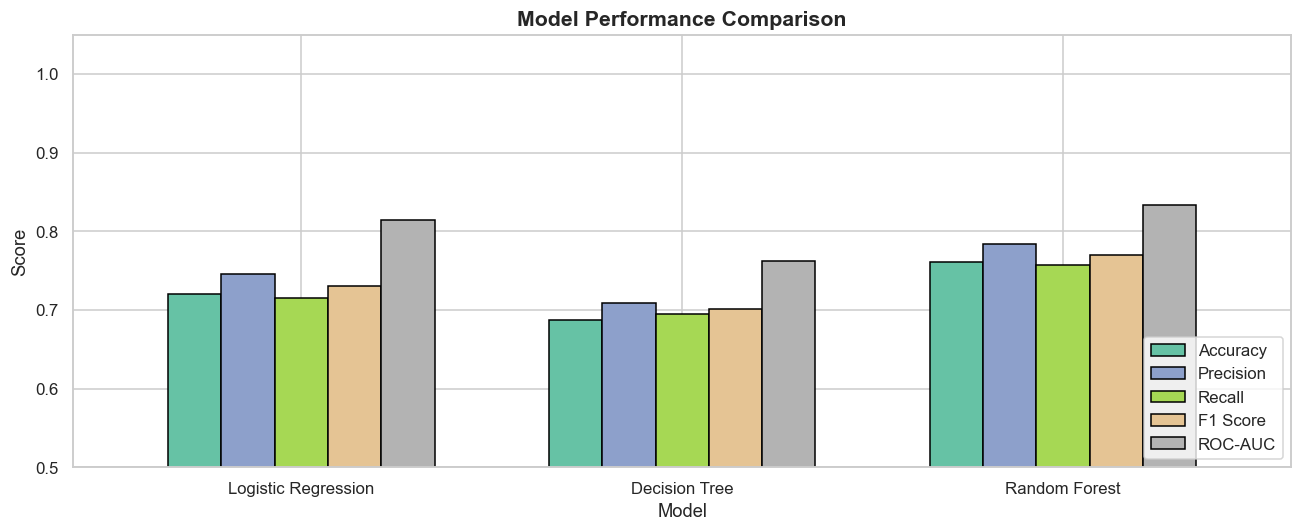

In [18]:
# ── 7.2  Bar Chart: Metric Comparison Across Models ──────────────────────────
results_df.plot(
    kind='bar',
    figsize=(12, 5),
    colormap='Set2',
    edgecolor='black',
    width=0.7
)
plt.title('Model Performance Comparison', fontsize=14, fontweight='bold')
plt.xlabel('Model')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0.5, 1.05)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [19]:
# ── 7.3  Detailed Evaluation of Best Model: Random Forest ────────────────────
best_model = models['Random Forest']
y_pred_rf = best_model.predict(X_test_scaled)
y_prob_rf = best_model.predict_proba(X_test_scaled)[:, 1]

print('=== Classification Report — Random Forest ===')
print('\nThis report shows Precision, Recall, and F1-Score for each class:\n')
print(classification_report(y_test, y_pred_rf,
                             target_names=['Poor Wine (0)', 'Good Wine (1)']))

=== Classification Report — Random Forest ===

This report shows Precision, Recall, and F1-Score for each class:

               precision    recall  f1-score   support

Poor Wine (0)       0.74      0.77      0.75       128
Good Wine (1)       0.78      0.76      0.77       144

     accuracy                           0.76       272
    macro avg       0.76      0.76      0.76       272
 weighted avg       0.76      0.76      0.76       272



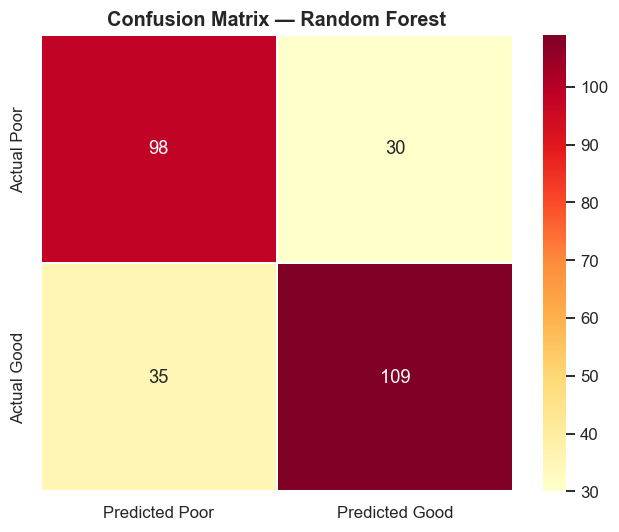

True Positives  (TP): 109  → Correctly identified Good wines
True Negatives  (TN): 98  → Correctly identified Poor wines
False Positives (FP): 30  → Poor wine wrongly called Good
False Negatives (FN): 35  → Good wine wrongly called Poor


In [20]:
# ── 7.4  Confusion Matrix ──────────────────────────────────────────────────────
# Rows = Actual label, Columns = Predicted label
# [TP  FP]      TP = Correctly predicted Good
# [FN  TN]      FN = Missed a Good wine (predicted Poor)
#               FP = Falsely predicted Good (actually Poor)
#               TN = Correctly predicted Poor

cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='YlOrRd',
            xticklabels=['Predicted Poor', 'Predicted Good'],
            yticklabels=['Actual Poor', 'Actual Good'],
            linewidths=1)
plt.title('Confusion Matrix — Random Forest', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'True Positives  (TP): {tp}  → Correctly identified Good wines')
print(f'True Negatives  (TN): {tn}  → Correctly identified Poor wines')
print(f'False Positives (FP): {fp}  → Poor wine wrongly called Good')
print(f'False Negatives (FN): {fn}  → Good wine wrongly called Poor')

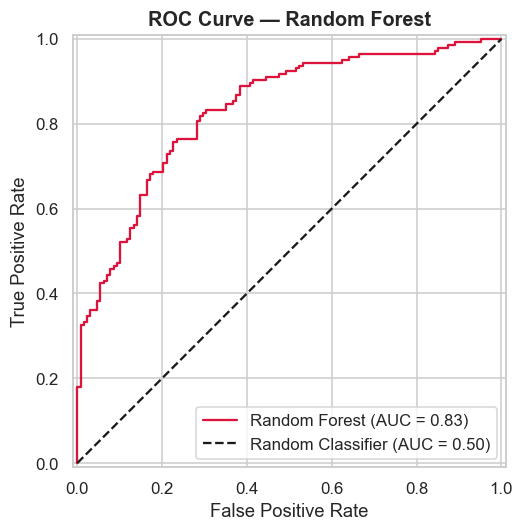

In [21]:
# ── 7.5  ROC Curve ────────────────────────────────────────────────────
# ROC curve plots True Positive Rate vs False Positive Rate at various thresholds
# AUC (Area Under Curve) → closer to 1.0 = better model
# A random model has AUC = 0.5 (diagonal line)

fig, ax = plt.subplots(figsize=(7, 5))

# FIX: from_predictions() does not accept 'color' in older sklearn versions.
# Instead: plot into an ax, then set color on the returned display line.
disp = RocCurveDisplay.from_predictions(
    y_test, y_prob_rf,
    name='Random Forest',
    ax=ax
)
disp.line_.set_color('crimson')   # Set color AFTER plotting

ax.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.50)')  # Baseline
ax.set_title('ROC Curve — Random Forest', fontsize=13, fontweight='bold')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

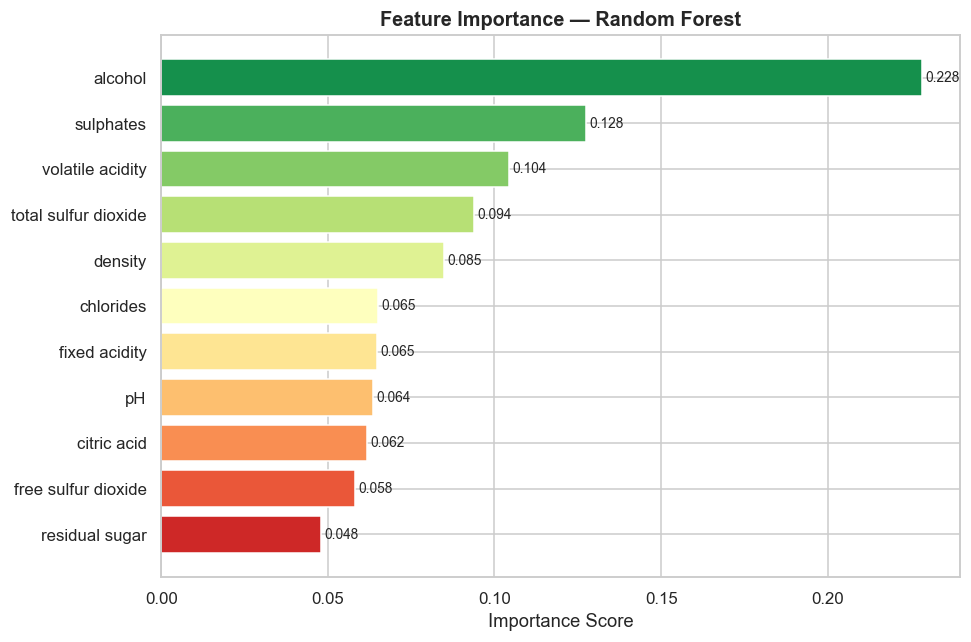

Top 3 Most Important Features:
         Feature  Importance
         alcohol    0.228360
       sulphates    0.127506
volatile acidity    0.104347


In [22]:
# ── 7.6  Feature Importance ───────────────────────────────────────────────────
# Random Forest tells us which features contributed most to its decisions
# Higher importance = that feature was used more in the forest's trees

importances = best_model.feature_importances_   # Array of importance scores
feature_names = X.columns

# Create a sorted dataframe for plotting
feat_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_df = feat_df.sort_values('Importance', ascending=True)  # Sort for horizontal bar

plt.figure(figsize=(9, 6))
bars = plt.barh(feat_df['Feature'], feat_df['Importance'],
                color=sns.color_palette('RdYlGn', len(feat_df)))
plt.xlabel('Importance Score')
plt.title('Feature Importance — Random Forest', fontsize=13, fontweight='bold')

# Add value labels on each bar
for bar, val in zip(bars, feat_df['Importance']):
    plt.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
             f'{val:.3f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

print('Top 3 Most Important Features:')
print(feat_df.sort_values('Importance', ascending=False).head(3).to_string(index=False))

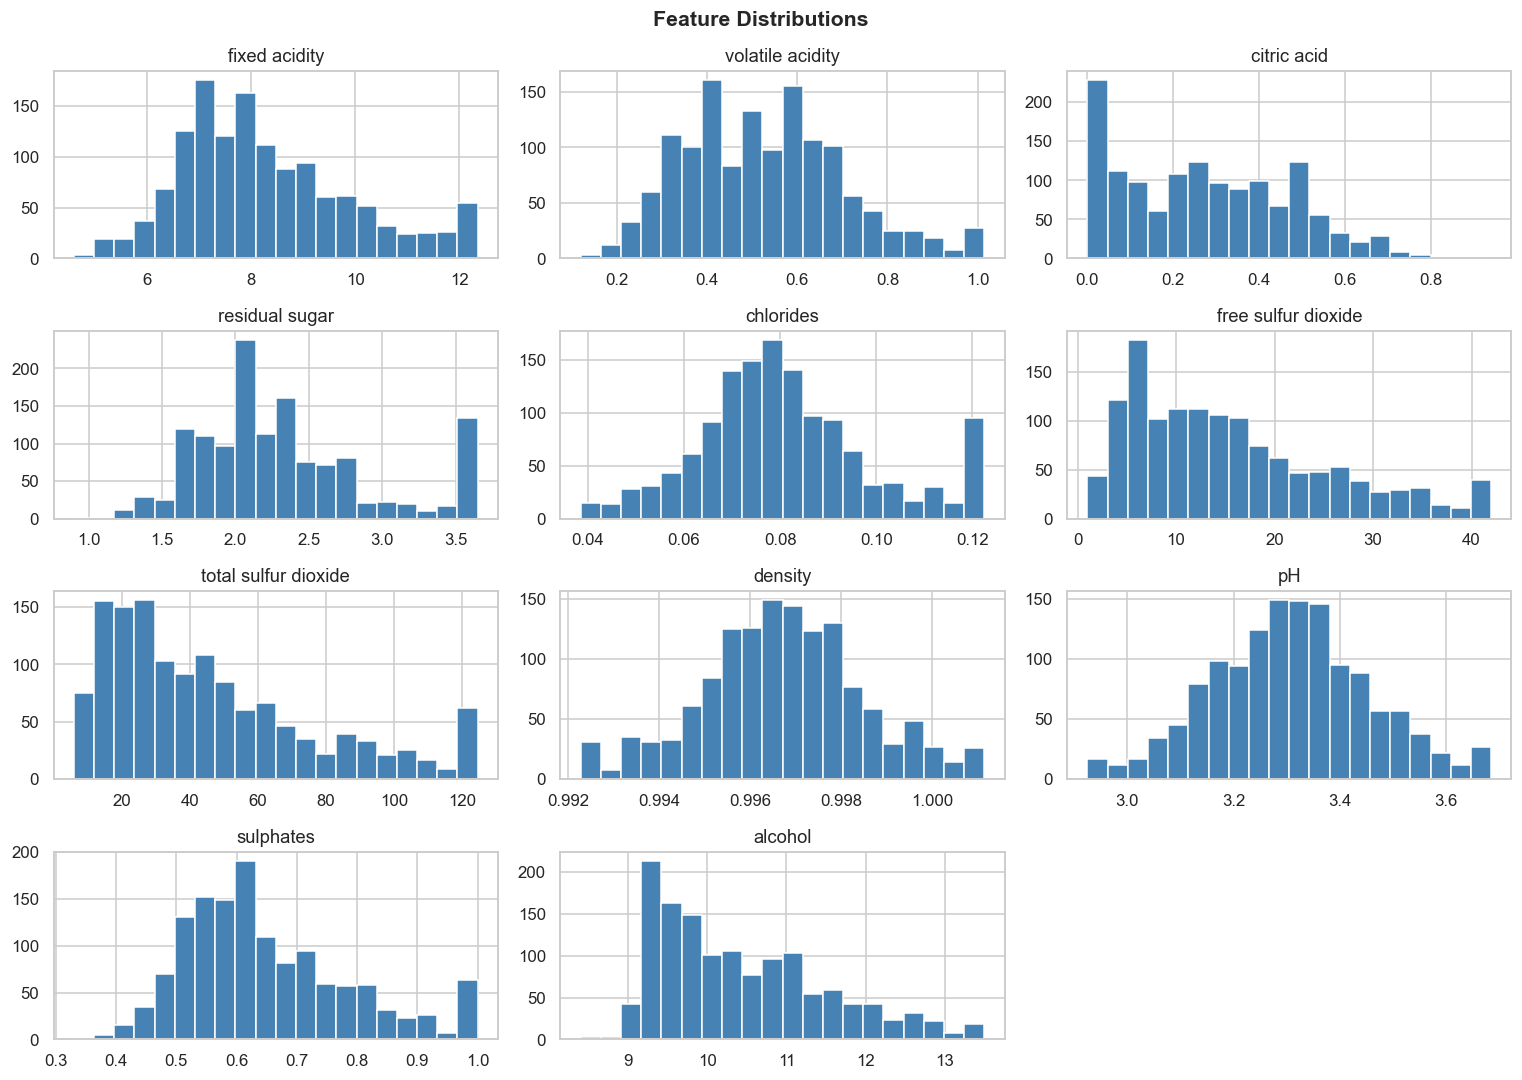

In [23]:
# ── 7.7  Histogram: Distribution of All Features ─────────────────────────────
# Understand what values each feature takes — helps spot skewness

X.hist(bins=20, figsize=(14, 10), color='steelblue', edgecolor='white')
plt.suptitle('Feature Distributions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

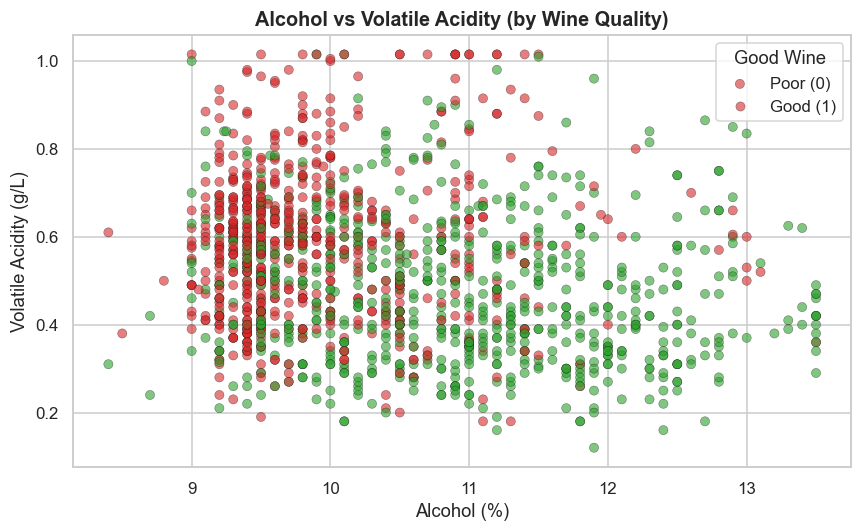

In [24]:
# ── 7.8  Scatter Plot: Alcohol vs Volatile Acidity (colored by label) ─────────
# Top 2 most important features visualized — shows separability

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='alcohol',
    y='volatile acidity',
    hue='good_wine',
    palette={0: '#d62728', 1: '#2ca02c'},
    alpha=0.6,
    edgecolor='k',
    linewidth=0.3
)
plt.title('Alcohol vs Volatile Acidity (by Wine Quality)', fontsize=13, fontweight='bold')
plt.xlabel('Alcohol (%)')
plt.ylabel('Volatile Acidity (g/L)')
plt.legend(title='Good Wine', labels=['Poor (0)', 'Good (1)'])
plt.tight_layout()
plt.show()

---
## ✅ Summary

| Step | What We Did |
|------|-------------|
| **Dataset** | Red Wine Quality — 1,599 samples, 11 features |
| **Target** | Binary: Good Wine (1) vs Poor Wine (0) |
| **Preprocessing** | Removed duplicates, capped outliers with IQR, scaled features |
| **Split** | 80% Train / 20% Test (stratified) |
| **Models** | Logistic Regression, Decision Tree, **Random Forest** |
| **Best Model** | Random Forest |
| **Key Metrics** | Accuracy, Precision, Recall, F1 Score, ROC-AUC |
| **Top Features** | Alcohol, Volatile Acidity, Sulphates |

### 📌 Key Takeaways for Viva
- **Why binary classification?** Original quality is 0–10 — too sparse. Grouping into Good/Poor makes the task learnable.
- **Why StandardScaler?** Features have very different ranges (alcohol: 8–15, sulfur dioxide: 0–300). Scaling ensures no feature dominates.
- **Why fit scaler only on train?** To prevent **data leakage** — the model must not see test data statistics during training.
- **Why Random Forest?** It is an ensemble of 100 decision trees — reduces overfitting through averaging (bagging).
- **F1 Score vs Accuracy?** F1 is better when classes are imbalanced; it balances precision and recall.